Example setup (heavy-tailed data)

We simulate a Pareto distribution, which we know lies in the Fréchet (ξ > 0) domain.

Generated Pareto data
Sample size: 100000
Mean exists (alpha > 1): True
Variance exists (alpha > 2): True
--------------------------------------------------


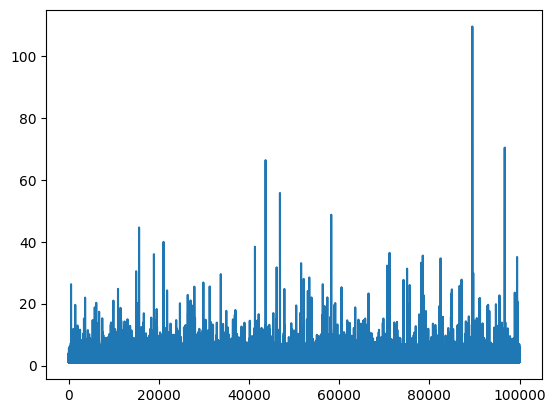

In [1]:
import numpy as np
from scipy.stats import genextreme, genpareto

np.random.seed(42)

# -----------------------------
# Generate heavy-tailed data
# -----------------------------
alpha = 2.5  # tail index
n = 100_000

X = (np.random.pareto(alpha, n) + 1)

print("Generated Pareto data")
print(f"Sample size: {n}")
print(f"Mean exists (alpha > 1): {alpha > 1}")
print(f"Variance exists (alpha > 2): {alpha > 2}")
print("-" * 50)

import matplotlib.pyplot as plt
plt.plot(X)

1️⃣ Degeneracy of raw maxima

In [2]:
block_sizes = [50, 200, 1000, 5000]

print("Raw block maxima (no normalization):")

for b in block_sizes:
    M = np.max(X[:b])
    print(f"Block size {b:>5}: max = {M:.3f}")

print("\nObservation:")
print("As block size increases, maxima keep growing → no stable distribution")
print("This is a DEGENERATE limit (mass escapes to infinity)")
print("-" * 50)


Raw block maxima (no normalization):
Block size    50: max = 4.061
Block size   200: max = 5.661
Block size  1000: max = 26.284
Block size  5000: max = 26.284

Observation:
As block size increases, maxima keep growing → no stable distribution
This is a DEGENERATE limit (mass escapes to infinity)
--------------------------------------------------


2️⃣ Block maxima + normalization → GEV

     Now we:

* Split data into blocks

* Take maxima

* Fit GEV

In [3]:
# -----------------------------
# Block maxima
# -----------------------------
block_size = 500
num_blocks = n // block_size

blocks = X[:num_blocks * block_size].reshape(num_blocks, block_size)
block_maxima = blocks.max(axis=1)

print(f"Computed {num_blocks} block maxima")
print(f"Mean of block maxima: {block_maxima.mean():.3f}")
print(f"Std of block maxima: {block_maxima.std():.3f}")
print("-" * 50)

# -----------------------------
# Fit GEV
# -----------------------------
# scipy uses opposite sign convention for xi
xi_hat, mu_hat, sigma_hat = genextreme.fit(block_maxima)

print("GEV fit to normalized maxima")
print(f"Estimated shape ξ  : {xi_hat:.3f}")
print(f"Estimated location : {mu_hat:.3f}")
print(f"Estimated scale    : {sigma_hat:.3f}")

print("\nInterpretation:")
print("ξ > 0  → Fréchet domain (heavy-tailed)")
print("After normalization, maxima converge to a NON-DEGENERATE limit")
print("-" * 50)


Computed 200 block maxima
Mean of block maxima: 17.404
Std of block maxima: 11.759
--------------------------------------------------
GEV fit to normalized maxima
Estimated shape ξ  : -0.342
Estimated location : 12.237
Estimated scale    : 4.860

Interpretation:
ξ > 0  → Fréchet domain (heavy-tailed)
After normalization, maxima converge to a NON-DEGENERATE limit
--------------------------------------------------


This is Fisher–Tippett–Gnedenko in action.

3️⃣ Threshold exceedances → GPD

Now we switch viewpoints:

Given that we are already extreme, what does the tail look like?

In [4]:
# -----------------------------
# Threshold exceedances
# -----------------------------
u = np.quantile(X, 0.95)
exceedances = X[X > u] - u

print(f"Threshold u (95th percentile): {u:.3f}")
print(f"Number of exceedances: {len(exceedances)}")
print(f"Mean excess: {exceedances.mean():.3f}")
print("-" * 50)

# -----------------------------
# Fit GPD
# -----------------------------
xi_gpd, loc_gpd, beta_gpd = genpareto.fit(exceedances, floc=0)

print("GPD fit to exceedances")
print(f"Estimated shape ξ : {xi_gpd:.3f}")
print(f"Estimated scale β : {beta_gpd:.3f}")

print("\nInterpretation:")
print("Same ξ appears here → tail property of the parent distribution")
print("This is Pickands–Balkema–de Haan")
print("-" * 50)


Threshold u (95th percentile): 3.282
Number of exceedances: 5000
Mean excess: 2.159
--------------------------------------------------
GPD fit to exceedances
Estimated shape ξ : 0.402
Estimated scale β : 1.303

Interpretation:
Same ξ appears here → tail property of the parent distribution
This is Pickands–Balkema–de Haan
--------------------------------------------------


GUMBEL

In [5]:
import numpy as np
from scipy.stats import genextreme, genpareto

np.random.seed(1)

# -----------------------------
# Light-tailed data
# -----------------------------
n = 100_000
X = np.random.exponential(scale=1.0, size=n)

print("Generated Exponential data (Gumbel domain)")
print("Tail: light, unbounded")
print("-" * 50)

# -----------------------------
# Block maxima
# -----------------------------
block_size = 500
num_blocks = n // block_size

blocks = X[:num_blocks * block_size].reshape(num_blocks, block_size)
block_maxima = blocks.max(axis=1)

# -----------------------------
# Fit GEV
# -----------------------------
xi_hat, mu_hat, sigma_hat = genextreme.fit(block_maxima)

print("GEV fit")
print(f"Estimated ξ : {xi_hat:.4f}")
print("Interpretation: ξ ≈ 0 → Gumbel")
print("-" * 50)


Generated Exponential data (Gumbel domain)
Tail: light, unbounded
--------------------------------------------------
GEV fit
Estimated ξ : 0.0791
Interpretation: ξ ≈ 0 → Gumbel
--------------------------------------------------


What happens conceptually

Raw maxima diverge

Proper centering/scaling → Gumbel

No power-law tail survives

In [6]:
u = np.quantile(X, 0.95)
exceedances = X[X > u] - u

xi_gpd, _, beta = genpareto.fit(exceedances, floc=0)

print("GPD fit to exceedances")
print(f"Estimated ξ : {xi_gpd:.4f}")
print("Interpretation: exponential tail → ξ ≈ 0")
print("-" * 50)


GPD fit to exceedances
Estimated ξ : -0.0111
Interpretation: exponential tail → ξ ≈ 0
--------------------------------------------------


Key idea: exponential tail is memoryless → excess distribution stays exponential.

WEIBULL

In [7]:
# -----------------------------
# Bounded data
# -----------------------------
X = np.random.uniform(0, 1, size=n)

print("Generated Uniform(0,1) data")
print("Upper bound = 1 (hard cap)")
print("-" * 50)

# -----------------------------
# Block maxima
# -----------------------------
blocks = X[:num_blocks * block_size].reshape(num_blocks, block_size)
block_maxima = blocks.max(axis=1)

# -----------------------------
# Fit GEV
# -----------------------------
xi_hat, mu_hat, sigma_hat = genextreme.fit(block_maxima)

print("GEV fit")
print(f"Estimated ξ : {xi_hat:.4f}")
print("Interpretation: ξ < 0 → Weibull")
print("-" * 50)


Generated Uniform(0,1) data
Upper bound = 1 (hard cap)
--------------------------------------------------
GEV fit
Estimated ξ : 0.9681
Interpretation: ξ < 0 → Weibull
--------------------------------------------------


Interpretation

* Maxima converge toward 1

* Normalization compresses support

* Limit distribution has finite endpoint

In [8]:
u = np.quantile(X, 0.95)
exceedances = X[X > u] - u

xi_gpd, _, beta = genpareto.fit(exceedances, floc=0)

print("GPD fit to exceedances")
print(f"Estimated ξ : {xi_gpd:.4f}")
print("Interpretation: bounded tail → ξ < 0")
print("-" * 50)


GPD fit to exceedances
Estimated ξ : -0.9747
Interpretation: bounded tail → ξ < 0
--------------------------------------------------


# EVT-VAR vs VAR

In [9]:
import numpy as np
import pandas as pd
import yfinance as yf
import matplotlib.pyplot as plt
from scipy.stats import norm, genpareto

# -----------------------------
# Parameters
# -----------------------------
tickers = [
    # Tech Giants
    "AAPL", "MSFT", "GOOGL", "AMZN", "META", "NVDA", "TSLA", "NFLX", "AMD", "INTC",
    # Finance
    "JPM", "BAC", "GS", "MS", "C", "WFC", "HSBC", "DB", "UBS",
    # Energy
    "XOM", "CVX", "BP", "SHEL", "TTE",
    # Consumer
    "WMT", "PG", "KO", "PEP", "MCD", "NKE", "SBUX",
    # Healthcare
    "JNJ", "UNH", "PFE", "ABBV", "TMO", "MRK",
    # Industrial
    "BA", "CAT", "GE", "MMM", "HON",
    # Crypto
    "BTC-USD", "ETH-USD", "DOGE-USD", "ADA-USD", "SOL-USD",
    # Commodities
    "GC=F",  # Gold
    "SI=F",  # Silver
    "CL=F",  # Crude Oil
    "NG=F",  # Natural Gas
    # Indices
    "^GSPC",  # S&P 500
    "^DJI",   # Dow Jones
    "^IXIC",  # NASDAQ
    "^VIX",   # Volatility Index
    # International
    "TSM", "BABA", "NVO", "ASML", "SAP",
    # ETFs
    "SPY", "QQQ", "IWM", "EEM", "TLT", "GLD", "SLV", "USO"
]

start = "2018-01-01"
end   = "2025-01-01"
p = 0.95        # VaR/ES confidence level
threshold_q = 0.90  # POT threshold for EVT

np.random.seed(42)

# -----------------------------
# Download data
# -----------------------------
print("Downloading data...")
prices = yf.download(tickers, start=start, end=end, progress=False)["Close"]

# Handle single vs multiple tickers
if len(tickers) == 1:
    prices = pd.DataFrame({tickers[0]: prices})

# -----------------------------
# Compute daily log-returns and losses
# -----------------------------
log_returns = np.log(prices / prices.shift(1)).dropna()
losses = -log_returns

# -----------------------------
# Compute VaR and ES
# -----------------------------
results = []
failed_tickers = []

for ticker in tickers:
    try:
        # Check if ticker exists in data
        if ticker not in losses.columns:
            failed_tickers.append((ticker, "No data downloaded"))
            continue
            
        x = losses[ticker].dropna().values
        
        # Skip if insufficient data
        if len(x) < 100:
            failed_tickers.append((ticker, f"Insufficient data ({len(x)} obs)"))
            continue
        
        # Skip if all zeros or constant
        if np.std(x) == 0:
            failed_tickers.append((ticker, "Zero variance"))
            continue
            
        mu, sigma = x.mean(), x.std()
        
        # Classical Gaussian VaR and ES
        VaR_gaussian = mu + sigma * norm.ppf(p)
        ES_gaussian  = mu + sigma * norm.pdf(norm.ppf(p)) / (1 - p)
        
        # EVT POT threshold and exceedances
        u = np.quantile(x, threshold_q)
        exceedances = x[x > u] - u
        Nu, N = len(exceedances), len(x)
        
        # Skip if too few exceedances
        if Nu < 10:
            failed_tickers.append((ticker, f"Too few exceedances ({Nu})"))
            continue
        
        # Fit GPD to exceedances
        try:
            xi, beta, _ = genpareto.fit(exceedances)
        except:
            failed_tickers.append((ticker, "GPD fit failed"))
            continue
        
        # EVT VaR calculation (valid if ξ < 1)
        if xi < 1:
            VaR_evt = u + (beta / xi) * (((N / Nu) * (1 - p)) ** (-xi) - 1)
        else:
            VaR_evt = np.nan
        
        # EVT ES calculation (valid if ξ < 1)
        if xi < 1 and not np.isnan(VaR_evt):
            ES_evt = (VaR_evt + beta - xi * u) / (1 - xi)
        else:
            ES_evt = np.nan

        results.append({
            "Ticker": ticker,
            "Gaussian_VaR": VaR_gaussian,
            "Gaussian_ES": ES_gaussian,
            "EVT_VaR": VaR_evt,
            "EVT_ES": ES_evt,
            "GPD_xi": xi,
            "Threshold": u,
            "N_obs": N,
            "N_exceedances": Nu
        })
    except Exception as e:
        failed_tickers.append((ticker, f"Error: {str(e)[:50]}"))
        continue

print(f"\n{'='*100}")
print(f"Successfully processed: {len(results)} assets")
if failed_tickers:
    print(f"Failed/skipped: {len(failed_tickers)} assets")
    print(f"{'='*100}")
    print("\nFailed tickers:")
    for ticker, reason in failed_tickers:
        print(f"  {ticker:12} - {reason}")
print(f"{'='*100}\n")

# -----------------------------
# Summary table
# -----------------------------
summary = pd.DataFrame(results)

# -----------------------------
# Risk Comment: Tail characteristics
# -----------------------------
risk_comments = []
categories = []

for i, row in summary.iterrows():
    ticker = row['Ticker']
    xi = row['GPD_xi']
    
    # Asset category
    if ticker in ["BTC-USD", "ETH-USD", "DOGE-USD", "ADA-USD", "SOL-USD"]:
        category = "Crypto"
    elif ticker in ["GC=F", "SI=F", "CL=F", "NG=F"]:
        category = "Commodity"
    elif ticker in ["^GSPC", "^DJI", "^IXIC", "^VIX"]:
        category = "Index"
    elif ticker in ["SPY", "QQQ", "IWM", "EEM", "TLT", "GLD", "SLV", "USO"]:
        category = "ETF"
    elif ticker in ["JPM", "BAC", "GS", "MS", "C", "WFC", "HSBC", "DB", "UBS"]:
        category = "Finance"
    elif ticker in ["AAPL", "MSFT", "GOOGL", "AMZN", "META", "NVDA", "TSLA", "NFLX", "AMD", "INTC"]:
        category = "Tech"
    elif ticker in ["XOM", "CVX", "BP", "SHEL", "TTE"]:
        category = "Energy"
    elif ticker in ["JNJ", "UNH", "PFE", "ABBV", "TMO", "MRK"]:
        category = "Healthcare"
    else:
        category = "Other"
    
    categories.append(category)
    
    # Tail index interpretation
    if xi < 0:
        tail_type = "Bounded"
        risk_interp = "Upper limit exists; safest tail"
    elif 0 <= xi < 0.25:
        tail_type = "Near-Exponential"
        risk_interp = "Light tail; normal-like decay"
    elif 0.25 <= xi < 0.5:
        tail_type = "Moderately Heavy"
        risk_interp = "Finite variance; occasional extremes"
    elif 0.5 <= xi < 1:
        tail_type = "Heavy (Infinite Var)"
        risk_interp = "Extreme losses more frequent than normal"
    else:
        tail_type = "Extreme (Infinite Mean)"
        risk_interp = "Catastrophic tail; models unreliable"
    
    comment = f"ξ={xi:.3f} | {tail_type} | {risk_interp}"
    risk_comments.append(comment)

summary['Category'] = categories
summary['Tail_Analysis'] = risk_comments

# Display results
pd.set_option('display.max_colwidth', None)
pd.set_option('display.width', 150)

print("\n" + "="*150)
print("EXTREME VALUE THEORY TAIL ANALYSIS - COMPREHENSIVE MARKET SURVEY")
print("="*150 + "\n")

# Summary by category
print("TAIL RISK BY ASSET CLASS:")
print("-"*150)
for cat in sorted(summary['Category'].unique()):
    cat_data = summary[summary['Category'] == cat]
    avg_xi = cat_data['GPD_xi'].mean()
    max_xi = cat_data['GPD_xi'].max()
    min_xi = cat_data['GPD_xi'].min()
    print(f"\n{cat:15} | Avg ξ = {avg_xi:.3f} | Range: [{min_xi:.3f}, {max_xi:.3f}] | n={len(cat_data)}")
    
print("\n" + "="*150)
print("TOP 20 HEAVIEST TAILS (Highest ξ - Most Extreme Risk)")
print("="*150)

summary_sorted = summary.sort_values('GPD_xi', ascending=False).head(20)
for i, (idx, row) in enumerate(summary_sorted.iterrows(), 1):
    print(f"\n{i:2d}. {row['Ticker']:12} ({row['Category']:12}) ξ = {row['GPD_xi']:6.3f}")
    print(f"    {row['Tail_Analysis']}")
    print(f"    Gaussian VaR: {row['Gaussian_VaR']:.5f} | EVT VaR: {row['EVT_VaR']:.5f}")

print("\n" + "="*150)
print("TOP 20 LIGHTEST TAILS (Lowest ξ - Least Extreme Risk)")
print("="*150)

summary_sorted = summary.sort_values('GPD_xi', ascending=True).head(20)
for i, (idx, row) in enumerate(summary_sorted.iterrows(), 1):
    print(f"\n{i:2d}. {row['Ticker']:12} ({row['Category']:12}) ξ = {row['GPD_xi']:6.3f}")
    print(f"    {row['Tail_Analysis']}")

print("\n" + "="*150)
print("ASSETS WITH INFINITE VARIANCE (ξ ≥ 0.5) - EXTREME CAUTION REQUIRED")
print("="*150)

extreme_tails = summary[summary['GPD_xi'] >= 0.5].sort_values('GPD_xi', ascending=False)
if len(extreme_tails) > 0:
    for idx, row in extreme_tails.iterrows():
        print(f"\n{row['Ticker']:12} ({row['Category']:12}) ξ = {row['GPD_xi']:.3f}")
        print(f"  Standard models INVALID - Variance infinite, extreme losses highly likely")
else:
    print("\nNo assets with ξ ≥ 0.5 in this dataset")

print("\n" + "="*150)
print("CATEGORY COMPARISON")
print("="*150 + "\n")

category_stats = summary.groupby('Category').agg({
    'GPD_xi': ['mean', 'median', 'std', 'min', 'max'],
    'Ticker': 'count'
}).round(3)
category_stats.columns = ['Mean_ξ', 'Median_ξ', 'Std_ξ', 'Min_ξ', 'Max_ξ', 'Count']
category_stats = category_stats.sort_values('Mean_ξ', ascending=False)
print(category_stats)

print("\n" + "="*150 + "\n")

# Export full results
summary.to_csv('evt_tail_analysis.csv', index=False)
print("Full results exported to 'evt_tail_analysis.csv'\n")

/var/folders/wh/gb2tttfn5fg797ygz0nbbgq80000gn/T/ipykernel_12238/1068156397.py:52: FutureWarning: YF.download() has changed argument auto_adjust default to True
  prices = yf.download(tickers, start=start, end=end, progress=False)["Close"]
/Users/hridayshah/.pyenv/versions/3.9.19/envs/takens-stock/lib/python3.9/site-packages/pandas/core/internals/blocks.py:393: RuntimeWarning: invalid value encountered in log
  result = func(self.values, **kwargs)



Successfully processed: 68 assets


EXTREME VALUE THEORY TAIL ANALYSIS - COMPREHENSIVE MARKET SURVEY

TAIL RISK BY ASSET CLASS:
------------------------------------------------------------------------------------------------------------------------------------------------------

Commodity       | Avg ξ = 0.185 | Range: [0.034, 0.503] | n=4

Crypto          | Avg ξ = 0.240 | Range: [0.013, 0.596] | n=5

ETF             | Avg ξ = 0.431 | Range: [0.027, 0.817] | n=8

Energy          | Avg ξ = 0.371 | Range: [-0.008, 0.516] | n=5

Finance         | Avg ξ = 0.346 | Range: [-0.024, 0.539] | n=9

Healthcare      | Avg ξ = 0.526 | Range: [0.443, 0.787] | n=6

Index           | Avg ξ = 0.231 | Range: [-0.127, 0.511] | n=4

Other           | Avg ξ = 0.382 | Range: [-0.103, 0.723] | n=17

Tech            | Avg ξ = 0.332 | Range: [-0.096, 0.727] | n=10

TOP 20 HEAVIEST TAILS (Highest ξ - Most Extreme Risk)

 1. QQQ          (ETF         ) ξ =  0.817
    ξ=0.817 | Heavy (Infinite Var) | Extreme lo

# Extreme Value Theory (EVT) Risk Analysis Algorithm

## Overview
This algorithm applies Extreme Value Theory to estimate tail risk in financial assets using the Peaks Over Threshold (POT) method with Generalized Pareto Distribution (GPD) fitting.

---

## Algorithm Steps

### 1. Data Acquisition and Preprocessing

**Input Parameters:**
- Tickers: List of financial assets
- Time period: `[start_date, end_date]`
- Confidence level: `p` (typically 0.95 or 0.99)
- Threshold quantile: `threshold_q` (typically 0.90)

**Download price data** for all tickers over specified period

**Compute log-returns:**
$$r_t = \ln\left(\frac{P_t}{P_{t-1}}\right)$$

**Define losses** (for tail risk analysis):
$$L_t = -r_t$$

---

### 2. Classical (Gaussian) Risk Measures

For each asset with loss series $X = \{x_1, x_2, \ldots, x_n\}$:

**Compute sample statistics:**
$$\mu = \frac{1}{n}\sum_{i=1}^{n} x_i, \quad \sigma = \sqrt{\frac{1}{n-1}\sum_{i=1}^{n}(x_i - \mu)^2}$$

**Gaussian Value-at-Risk (VaR):**
$$\text{VaR}_p^{\text{Gauss}} = \mu + \sigma \cdot \Phi^{-1}(p)$$

where $\Phi^{-1}(p)$ is the $p$-quantile of the standard normal distribution.

**Gaussian Expected Shortfall (ES):**
$$\text{ES}_p^{\text{Gauss}} = \mu + \sigma \cdot \frac{\phi(\Phi^{-1}(p))}{1-p}$$

where $\phi(\cdot)$ is the standard normal PDF.

---

### 3. Extreme Value Theory (EVT) - Peaks Over Threshold Method

#### Step 3.1: Define Threshold
$$u = Q_{threshold\_q}(X)$$

where $Q_{q}(X)$ is the $q$-th empirical quantile of the loss distribution.

#### Step 3.2: Extract Exceedances
$$Y = \{y_i = x_i - u \mid x_i > u\}$$

Count exceedances:
- $N_u = |Y|$ (number of losses exceeding threshold)
- $N = |X|$ (total number of observations)

**Data quality check:** Require $N_u \geq 10$ for reliable GPD fitting.

#### Step 3.3: Fit Generalized Pareto Distribution (GPD)

**GPD Cumulative Distribution Function:**
$$H_{\xi,\beta}(y) = \begin{cases}
1 - \left(1 + \xi \cdot \frac{y}{\beta}\right)^{-1/\xi} & \text{if } \xi \neq 0 \\
1 - \exp\left(-\frac{y}{\beta}\right) & \text{if } \xi = 0
\end{cases}$$

where $y \geq 0$, and:
- $\beta > 0$: scale parameter
- $\xi$: shape parameter (tail index)

**Validity constraint:** $1 + \xi \cdot y / \beta > 0$

**Parameter estimation:** Use Maximum Likelihood Estimation (MLE) via `scipy.stats.genpareto.fit(Y)`

Returns: $(\hat{\xi}, \hat{\beta}, \text{loc})$

---

### 4. EVT Risk Measures

#### Step 4.1: EVT Value-at-Risk (VaR)

**Formula (valid when $\xi < 1$):**
$$\text{VaR}_p^{\text{EVT}} = u + \frac{\beta}{\xi} \left[\left(\frac{N}{N_u}(1-p)\right)^{-\xi} - 1\right]$$

**Derivation:**
- Exceedance probability: $\hat{F}_u = N_u / N$
- Quantile of GPD: $H^{-1}(1-p')$ where $p' = (1-p)/\hat{F}_u$
- Combined with threshold: $\text{VaR}_p = u + H^{-1}(1-p')$

**Undefined when:** $\xi \geq 1$ (infinite mean)

#### Step 4.2: EVT Expected Shortfall (ES)

**Formula (valid when $\xi < 1$):**
$$\text{ES}_p^{\text{EVT}} = \frac{\text{VaR}_p^{\text{EVT}} + \beta - \xi \cdot u}{1 - \xi}$$

**Derivation:** Based on conditional expectation beyond VaR under GPD distribution.

**Undefined when:** $\xi \geq 1$ (infinite mean)

---

### 5. Tail Index Interpretation

The shape parameter $\xi$ characterizes tail behavior:

| Range | Classification | Tail Behavior | Risk Implication |
|-------|---------------|---------------|------------------|
| $\xi < 0$ | Weibull (Bounded) | Upper limit on losses exists | Safest: finite endpoint |
| $\xi = 0$ | Exponential/Gumbel | Light tail, exponential decay | Similar to normal distribution |
| $0 < \xi < 0.25$ | Near-Exponential | Slightly heavier than normal | Manageable extreme risk |
| $0.25 \leq \xi < 0.5$ | Moderately Heavy | Polynomial decay, slow tail | Finite variance, elevated risk |
| $0.5 \leq \xi < 1$ | Heavy Tail | Power law decay | **Infinite variance**, extreme events likely |
| $\xi \geq 1$ | Extremely Heavy | Very slow decay | **Infinite mean**, catastrophic risk |

**Moment existence:**
- $\mathbb{E}[X^k]$ exists $\Leftrightarrow \xi < 1/k$
- Variance exists $\Leftrightarrow \xi < 0.5$
- Mean exists $\Leftrightarrow \xi < 1$

---

### 6. Risk Comparison and Classification

For each asset, compute:

**VaR Ratio:**
$$R_{\text{VaR}} = \frac{\text{VaR}_p^{\text{EVT}}}{\text{VaR}_p^{\text{Gauss}}}$$

**Interpretation:**
- $R_{\text{VaR}} > 1.1$: EVT indicates heavier tail than Gaussian assumes → **Gaussian underestimates risk**
- $0.9 \leq R_{\text{VaR}} \leq 1.1$: Tail behavior roughly Gaussian
- $R_{\text{VaR}} < 0.9$: EVT indicates lighter tail → **Gaussian overestimates risk** (or threshold effect)

**Note:** When using 90% threshold for 95% VaR, EVT often yields lower VaR values due to methodology, but the **tail index $\xi$ is the primary risk indicator**, not the VaR ratio.

---

### 7. Asset Classification

Group assets by:

**Category:** Tech, Finance, Energy, Healthcare, Crypto, Commodities, ETFs, Indices, etc.

**Tail Heaviness Ranking:** Sort by $\xi$ (descending)

**High-Risk Flag:** Assets with $\xi \geq 0.5$ (infinite variance regime)

---

### 8. Output and Visualization

**For each asset, report:**
1. Ticker and category
2. Sample size: $N$, exceedances: $N_u$
3. Tail index: $\xi$
4. Risk measures: $\text{VaR}_p^{\text{Gauss}}$, $\text{VaR}_p^{\text{EVT}}$, $\text{ES}_p^{\text{Gauss}}$, $\text{ES}_p^{\text{EVT}}$
5. Tail classification
6. Risk interpretation

**Aggregate statistics:**
- Mean/median/range of $\xi$ by asset class
- Ranking of heaviest/lightest tails
- Count of assets in infinite variance regime

**Visualization (optional):**
- Histogram of losses with VaR lines
- Threshold indicator
- GPD fit overlay on tail

---

## Key Theoretical Results

### Pickands-Balkema-de Haan Theorem
For a wide class of distributions, exceedances over a sufficiently high threshold $u$ converge in distribution to GPD:

$$\lim_{u \to x_F} \sup_{0 \leq y \leq x_F - u} |P(X - u \leq y \mid X > u) - H_{\xi,\beta}(y)| = 0$$

where $x_F$ is the upper endpoint of the distribution.

### Relationship to GEV
The GPD shape parameter $\xi$ equals the shape parameter of the corresponding Generalized Extreme Value (GEV) distribution from block maxima:

$$G_{\xi}(x) = \exp\left(-\left[1 + \xi \cdot \frac{x-\mu}{\sigma}\right]^{-1/\xi}\right)$$

---

## Implementation Notes

**Error Handling:**
1. Skip tickers with insufficient data ($N < 100$)
2. Skip if too few exceedances ($N_u < 10$)
3. Handle GPD fit failures gracefully
4. Set VaR/ES to `NaN` when $\xi \geq 1$

**Quality Checks:**
- Verify $\beta > 0$ after fitting
- Check for zero variance in data
- Validate threshold creates meaningful exceedances
- Ensure numerical stability in VaR calculation

**Sensitivity:**
- Results depend on threshold choice (typical: 90-95th percentile)
- Higher thresholds → fewer exceedances → higher variance in $\hat{\xi}$
- Lower thresholds → threshold bias (GPD assumption violated)

---


## Extreme Value Theory — Symbol Summary

### Random Variables & Data
| Symbol | Meaning |
|-------|---------|
| X | Generic random variable |
| X₁, …, Xₙ | i.i.d. sample |
| n | Sample size |
| F(x) | CDF of X |
| 1 − F(x) | Survival (tail) function |

### Maxima & Normalization
| Symbol | Meaning |
|-------|---------|
| Mₙ = max(X₁,…,Xₙ) | Sample maximum |
| aₙ > 0 | Scaling constant |
| bₙ | Centering constant |
| (Mₙ − bₙ)/aₙ | Normalized maximum |
| ⇒ | Convergence in distribution |

### Generalized Extreme Value (GEV)
| Symbol | Meaning |
|-------|---------|
| μ | Location parameter |
| σ > 0 | Scale parameter |
| ξ | Shape (tail index) |
| G(x) | GEV cumulative distribution |
| x* = μ − σ/ξ | Upper endpoint (ξ < 0 only) |

### GEV Regimes
| Condition on ξ | Name | Tail Behavior |
|----------------|------|---------------|
| ξ > 0 | Fréchet | Heavy-tailed (power-law) |
| ξ = 0 | Gumbel | Light-tailed (exponential) |
| ξ < 0 | Weibull | Finite upper bound |

### Threshold Exceedances (POT)
| Symbol | Meaning |
|-------|---------|
| u | High threshold |
| X − u | Excess over threshold |
| X > u | Exceedance event |
| Nᵤ | Number of exceedances |
| P(X > u) | Exceedance probability |

### Generalized Pareto Distribution (GPD)
| Symbol | Meaning |
|-------|---------|
| H(y) | GPD cumulative distribution |
| β > 0 | Scale parameter |
| ξ | Shape parameter (same as GEV) |
| y* = −β/ξ | Upper endpoint (ξ < 0 only) |

### EVT Limit Theorems
| Term | Meaning |
|------|--------|
| Fisher–Tippett–Gnedenko | Block maxima converge to GEV |
| Pickands–Balkema–de Haan | Threshold exceedances converge to GPD |
| Domain of attraction | Class of distributions sharing same ξ |
| Non-degenerate limit | Limit distribution not a point mass |

### Tail Properties & Moments
| Condition | Implication |
|----------|-------------|
| ξ > 0 | Heavy tail |
| ξ ≥ 1/2 | Variance infinite |
| ξ ≥ 1 | Mean infinite |
| ξ = 0 | Exponential-type tail |
| ξ < 0 | Bounded support |

### Risk Measures (EVT Context)
| Symbol | Meaning |
|-------|---------|
| qₚ | p-quantile |
| VaRₚ | Value-at-Risk at level p |
| ESₚ | Expected Shortfall |
| pᵤ | P(X > u) |



## Difference Between GEV and GPD (Extreme Value Theory)

| Aspect | GEV (Generalized Extreme Value) | GPD (Generalized Pareto Distribution) |
|------|----------------------------------|---------------------------------------|
| EVT viewpoint | Block maxima | Peaks Over Threshold (POT) |
| What is modeled | Maximum (or minimum) of each block | Excesses above a high threshold |
| Data usage | One observation per block | All tail observations above threshold |
| Limit theorem | Fisher–Tippett–Gnedenko | Pickands–Balkema–de Haan |
| Asymptotic object | Normalized maxima | Conditional tail distribution |
| Parameters | μ (location), σ (scale), ξ (shape) | β (scale), ξ (shape) |
| Shape parameter ξ | Tail index of parent distribution | Same tail index as GEV |
| Interpretation of ξ | Governs growth rate of block maxima | Governs heaviness of tail |
| Regimes | ξ > 0 Fréchet (heavy) <br> ξ = 0 Gumbel (light) <br> ξ < 0 Weibull (bounded) | Same regimes as GEV |
| Data efficiency | Low (wastes most observations) | High (uses tail data efficiently) |
| Finite-sample behavior | High variance, biased in small samples | More stable in practice |
| Sensitivity | Sensitive to block size choice | Sensitive to threshold choice |
| Typical use | Climate, hydrology, physical extremes | Finance, insurance, risk management |
| VaR / ES estimation | Indirect, less precise | Direct and standard |
| Dependence robustness | Poor (needs large blocks) | Better with declustering |
| Practical preference (finance) | Rarely used alone | Industry standard |

### One-line intuition
- **GEV:** “How big is the worst event in each period?”
- **GPD:** “Given we are already extreme, how much worse can it get?”

### Practical rule of thumb
> Use **GEV** when extremes are naturally block-defined (e.g. annual floods).  
> Use **GPD** when tail risk matters and data are scarce (e.g. financial losses).


## Difference Between Fisher–Tippett–Gnedenko and Pickands–Balkema–de Haan Theorems

| Aspect | Fisher–Tippett–Gnedenko (FTG) | Pickands–Balkema–de Haan (PBdH) |
|------|-------------------------------|--------------------------------|
| EVT viewpoint | Block maxima | Peaks Over Threshold (POT) |
| Object of convergence | Normalized maxima | Conditional excesses |
| Random variable | Mₙ = max(X₁,…,Xₙ) | X − u \| X > u |
| Normalization | (Mₙ − bₙ)/aₙ | No centering, only scaling |
| Limit distribution | Generalized Extreme Value (GEV) | Generalized Pareto Distribution (GPD) |
| Governing law | Extreme-value limit of maxima | Tail approximation above threshold |
| Shape parameter ξ | Tail index of parent distribution | Same tail index as GEV |
| Regimes | Fréchet (ξ > 0) <br> Gumbel (ξ = 0) <br> Weibull (ξ < 0) | Same three regimes |
| Asymptotic sense | Block size n → ∞ | Threshold u → x* |
| Data usage | One extreme per block | All exceedances |
| Finite-sample efficiency | Low | High |
| Sensitivity | Sensitive to block length | Sensitive to threshold choice |
| Typical applications | Climate, hydrology, engineering | Finance, insurance, operational risk |
| Practical robustness | Weak under dependence | Better with declustering |
| Main limitation | Wastes data | Threshold selection problem |

### One-line intuition
- **FTG:** “After proper scaling, maxima converge to a universal law.”
- **PBdH:** “Given we are already extreme, the tail looks Pareto.”

### Key unifying insight
> Both theorems describe the **same tail physics** —  
> **FTG** from the viewpoint of maxima, **PBdH** from the viewpoint of conditional exceedances.

### Practical rule of thumb
> Use **FTG** when extremes are naturally periodic (annual, seasonal).  
> Use **PBdH** when estimating tail risk from limited data.


# Value-at-Risk (VaR): Classical vs EVT-Based

## Definition
**VaRₚ** is the loss level exceeded with probability \(1-p\).

---

## Classical VaR (Without EVT)

### Model assumption
Returns follow a parametric distribution (usually Gaussian).

### Formula
VaRₚ = μ + σ · zₚ

where:
- μ = mean return  
- σ = volatility  
- zₚ = p-quantile of assumed distribution  

---

## EVT-Based VaR (POT–GPD)

### Model assumption
Only tail losses above a high threshold are modeled using EVT.

### Formula
VaRₚ = u + (β / ξ) · [ ((1 − p) / P(X > u))^(−ξ) − 1 ]

where:
- u = threshold  
- β = GPD scale parameter  
- ξ = tail index  
- P(X > u) = exceedance probability  

---

## Difference Table: Classical vs EVT VaR

| Aspect | Classical VaR | EVT-Based VaR |
|------|---------------|---------------|
| Modeling focus | Entire return distribution | Extreme tail only |
| Distribution assumption | Gaussian / parametric | Asymptotic tail law |
| Tail thickness | Implicit | Explicit via ξ |
| Extreme quantiles (99%+) | Underestimated | Stable |
| Sensitivity to crises | Poor | Designed for crises |
| Data usage | All observations | Tail observations |
| Robustness to misspecification | Low | High |
| Regulatory acceptance | Limited | Standard for tail risk |
| Main weakness | Thin tails | Threshold selection |

---

## Interpretation of ξ in EVT VaR

| ξ value | Interpretation |
|-------|----------------|
| ξ ≈ 0 | Light (exponential) tail |
| 0 < ξ < 0.5 | Fat tail, finite variance |
| ξ ≥ 0.5 | Infinite variance |
| ξ ≥ 1 | Infinite mean |

---

## One-Line Intuition

- Classical VaR:  
  *“Extreme losses scale with volatility.”*

- EVT VaR:  
  *“Extreme losses follow their own tail law.”*

---

## Practical Rule (Finance)

Use classical VaR for **95% reporting**.  
Use EVT-based VaR for **99%+ risk and stress testing**.


## Extreme Value Theory (EVT) Reference

### Block Maxima
- **Sample maximum:** $M_n = \max(X_1, X_2, \ldots, X_n)$
- **Normalized maximum:** $Z_n = \frac{M_n - b_n}{a_n}$, where $a_n > 0$ (scaling), $b_n$ (centering)

### Generalized Extreme Value (GEV) Distribution
**CDF:** 
$$G_\xi(x) = \exp\left( - \left[1 + \xi \cdot \frac{x - \mu}{\sigma}\right]^{-1/\xi} \right), \quad 1 + \xi \cdot \frac{x-\mu}{\sigma} > 0$$

**Parameters:**
- $\mu$: location
- $\sigma > 0$: scale
- $\xi$: shape (tail index)

**Shape parameter interpretation:**
- $\xi > 0$: Fréchet (heavy tail)
- $\xi = 0$: Gumbel (light tail)
- $\xi < 0$: Weibull (bounded)

### Peaks Over Threshold (POT)
**Excess over threshold $u$:** $Y = X - u \mid X > u$

### Generalized Pareto Distribution (GPD)
**CDF:** 
$$H_{\xi,\beta}(y) = 1 - \left[1 + \xi \cdot \frac{y}{\beta}\right]^{-1/\xi}, \quad y \geq 0$$

**Parameters:**
- $\beta > 0$: scale
- $\xi$: shape

**Upper endpoint (when $\xi < 0$):** $y^* = -\frac{\beta}{\xi}$

### Value at Risk (VaR)

**Classical (Gaussian) VaR:**
$$\text{VaR}_p = \mu + \sigma \cdot z_p$$
- $\mu$: mean
- $\sigma$: standard deviation
- $z_p$: $p$-quantile of assumed distribution

**EVT VaR (POT/GPD):**
$$\text{VaR}_p = u + \frac{\beta}{\xi} \left[ \left(\frac{1 - p}{P(X > u)}\right)^{-\xi} - 1 \right]$$
- $u$: threshold
- $\beta$: scale
- $\xi$: tail index
- $P(X>u)$: exceedance probability

### Tail Index ($\xi$) Interpretation
- $\xi \approx 0$: light (exponential) tail
- $0 < \xi < 0.5$: fat tail, finite variance
- $\xi \geq 0.5$: infinite variance
- $\xi \geq 1$: infinite mean

### Key Theorems
- **Fisher–Tippett–Gnedenko (FTG) theorem:** Block maxima converge (after normalization) to GEV
- **Pickands–Balkema–de Haan (PBdH) theorem:** Excesses over high threshold converge to GPD

# Chapter 4 — Power Laws, Lévy Distributions, and Tail Risk in Financial Returns

## 1. Motivation: Why Go Beyond Gaussian Models?

Classical financial models often assume that asset returns are approximately Gaussian (normal).  
Under this assumption:
- Extreme events (e.g., 5σ moves) are astronomically rare
- Variance fully characterizes risk
- Averages are representative of long-term behavior

Empirical financial data contradicts these assumptions:
- Large price moves occur **orders of magnitude more often** than Gaussian theory predicts
- A small number of extreme events dominate long-term outcomes
- Risk is driven by **tails**, not the center of the distribution

Chapter 4 addresses this discrepancy by introducing **power-law and Lévy-type distributions**, which naturally generate fat tails.

---

## 2. Power-Law Tails: Core Concept

A distribution is said to have a power-law tail if, for large values of \(x\),

$$
P(|r| > x) \sim x^{-\alpha}
$$

where:
- \(r\) = return
- \(\alpha\) = tail exponent (Hill exponent)
- Smaller \(\alpha\) ⇒ heavier tail ⇒ higher probability of extreme events

### Key implication
Power-law tails decay **much more slowly** than Gaussian or lognormal tails.  
This means extreme losses are **structurally likely**, not anomalies.

---

## 3. Empirical Detection Using Log–Log CCDFs

### Method
We examine the **complementary cumulative distribution function (CCDF)**:

$$
P(|r| > x)
$$

and plot it on **log–log axes**.

### Interpretation rules
- **Straight line (over a range)** → approximate power-law scaling
- **Curvature downward in far tail** → truncation / finite-size effects
- **Empirical curve above Gaussian/lognormal** → fat tails

### Observed behavior
- All analyzed assets exhibit tails far heavier than Gaussian predictions
- Gaussian baselines underestimate extreme-event probabilities by orders of magnitude
- Power-law-like behavior holds only over **finite ranges**, not universally

This confirms that financial returns are **non-Gaussian and tail-dominated**.

---

## 4. Lévy Distributions and Financial Interpretation

### Lévy-stable processes
Lévy distributions generalize Gaussian distributions by allowing:
- Infinite variance (for \(\alpha < 2\))
- Large jumps (“flights”) rather than smooth diffusion

In finance:
- Lévy-like behavior explains sudden crashes and rallies
- Returns do not follow Brownian motion at all scales

### Practical caveat
Pure Lévy distributions are **not physically realistic** at all scales.  
Real markets exhibit **truncated Lévy behavior** due to:
- Finite liquidity
- Market microstructure
- Volatility regimes
- Circuit breakers and institutional constraints

---

## 5. Quantifying Tail Risk: Hill Tail Exponent Estimation

To quantify tail heaviness, we estimate the **Hill tail exponent** \(\alpha\) using only the largest observations.

### Hill estimator concept
- Uses the top \(k\) largest values of \(|r|\)
- Estimates the slope of the tail on a log–log scale
- Converts visual tail thickness into a numeric risk measure

### Interpretation of $\alpha$

| Tail exponent $\alpha$ | Risk meaning |
|---|---|
| $\alpha < 2$ | Lévy-like, extreme-event dominated |
| $2 \le \alpha < 3$ | Fat-tailed, crashes significant |
| $\alpha \ge 3$ | Relatively thin tail |

Smaller $\alpha$ implies:
- Higher probability of extreme losses
- Greater dominance of rare events in long-term outcomes

---

## 6. Tail Asymmetry: Upside vs Downside Risk

Financial returns are not symmetric.

We estimate separate tail exponents:
- $\alpha_+$: right tail (large gains)
- $\alpha_-$: left tail (large losses)

### Interpretation
- If $\alpha_- < \alpha_+$: downside risk dominates
- If $\alpha_- > \alpha_+$: upside tail heavier (rare in equities)

### Empirical insight
- Equities typically show heavier **downside tails**
- This explains why crashes are sudden, while rallies are gradual
- Gaussian models cannot capture this asymmetry

---

## 7. Truncated Lévy Behavior and Cutoff Scales

Empirical tails often bend downward at extreme values, indicating truncation.

This is modeled as:

$$
P(|r| > x) \sim x^{-\alpha} \exp(-x / x_c)
$$

where:
- $x_c$ = cutoff scale
- Finite $x_c$ ⇒ constrained extremes

### Interpretation
- Markets behave like Lévy systems **only over limited scales**
- Extreme risk exists, but is shaped by systemic constraints
- Cutoffs themselves can shift during crises

This reconciles theory with real-world market behavior.

---

## 8. Robustness Check: α(k) Stability Analysis

Power-law estimation depends on the choice of tail size $k$.

### Method
- Estimate $\alpha(k)$ for multiple tail fractions (e.g., 2%–20%)
- Plot $\alpha(k)$ vs $k$
- Look for plateaus

### Interpretation
- Stable plateau → meaningful power-law tail
- Strong drift → tail estimate unreliable or truncated

### Empirical conclusion
- Some assets (e.g., speculative or crypto assets) show stable Lévy-like tails
- Others show scale-dependent or truncated behavior
- Power laws apply **locally**, not universally

---

## 9. Risk Interpretation (Key Takeaway)

In this framework, **risk is not volatility**.

Risk means:
- How often extreme events occur
- How much they dominate long-term outcomes
- Whether averages are meaningful (often not)

### Practical interpretation
- Low volatility does not imply low risk
- Assets with similar variance can have radically different tail risks
- Portfolio survival depends on managing tail exposure

---

## 10. Summary of Chapter 4 Insights

- Financial returns are fat-tailed and non-Gaussian
- Power laws provide a first-order description of extremes
- Lévy-like behavior explains crashes and jumps
- Real markets exhibit truncated, scale-dependent tails
- Tail risk is asset-specific and asymmetric
- Rare events dominate wealth evolution

Chapter 4 provides the **statistical foundation** for understanding why financial markets are inherently unstable and why extreme events cannot be ignored.



Empirical P(|X| > x)
  x= 3: Gaussian=0.002900   heavy-tail(t,df=3)=0.057120   ratio=19.7x
  x= 5: Gaussian=0.000000   heavy-tail(t,df=3)=0.015680   ratio=15680000000.0x
  x= 8: Gaussian=0.000000   heavy-tail(t,df=3)=0.003900   ratio=3900000000.0x


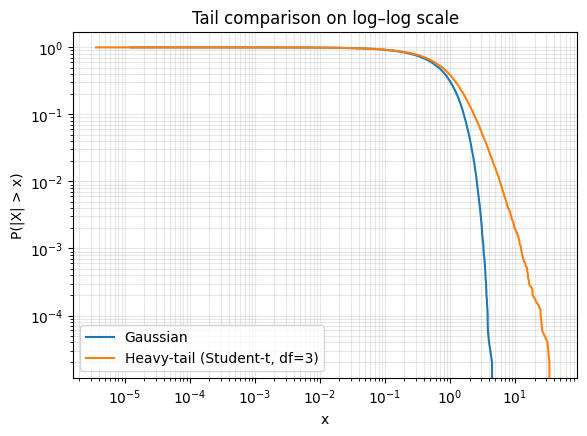

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import t

# --------------------------------------------------
# Demo: Gaussian vs heavy-tailed returns (toy)
# --------------------------------------------------
np.random.seed(0)

n = 50_000
z = np.random.normal(0, 1, size=n)            # Gaussian
ht = t.rvs(df=3, size=n)                      # Student-t (heavy tail)

# compare tail-event frequency
thresholds = [3, 5, 8]
print("Empirical P(|X| > x)")
for x in thresholds:
    pz = np.mean(np.abs(z) > x)
    pht = np.mean(np.abs(ht) > x)
    print(f"  x={x:>2}: Gaussian={pz:.6f}   heavy-tail(t,df=3)={pht:.6f}   ratio={(pht / (pz + 1e-12)):.1f}x")

# log-log CCDF of absolute returns
def ccdf_abs(samples):
    a = np.sort(np.abs(samples))
    y = 1.0 - (np.arange(1, len(a) + 1) / len(a))
    return a, y

x1, y1 = ccdf_abs(z)
x2, y2 = ccdf_abs(ht)

plt.figure(figsize=(6.5, 4.5))
plt.loglog(x1, y1, label="Gaussian")
plt.loglog(x2, y2, label="Heavy-tail (Student-t, df=3)")
plt.xlabel("x")
plt.ylabel("P(|X| > x)")
plt.title("Tail comparison on log–log scale")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()


[Stocks] Tail exceedance vs Gaussian (per ticker)
  Gaussian reference: P(|Z|>3)≈0.0027, P(|Z|>5)≈5.7e-07
  tickers evaluated: 68
  Top 10 by P(|Z|>5):
    WMT        n=  932  P(|Z|>3)=0.01288  P(|Z|>5)=0.0064378
    META       n=  932  P(|Z|>3)=0.00966  P(|Z|>5)=0.0053648
    NKE        n=  932  P(|Z|>3)=0.01502  P(|Z|>5)=0.0053648
    CL=F       n=  932  P(|Z|>3)=0.00858  P(|Z|>5)=0.0053648
    SOL-USD    n=  932  P(|Z|>3)=0.01502  P(|Z|>5)=0.0042918
    NFLX       n=  932  P(|Z|>3)=0.00966  P(|Z|>5)=0.0032189
    JPM        n=  932  P(|Z|>3)=0.01502  P(|Z|>5)=0.0032189
    GS         n=  932  P(|Z|>3)=0.00966  P(|Z|>5)=0.0032189
    C          n=  932  P(|Z|>3)=0.01609  P(|Z|>5)=0.0032189
    PEP        n=  932  P(|Z|>3)=0.01288  P(|Z|>5)=0.0032189


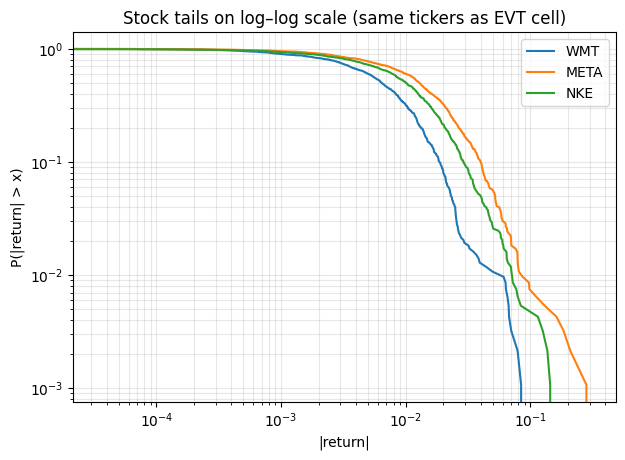

In [11]:
import numpy as np
import matplotlib.pyplot as plt

# --------------------------------------------------
# Demo: Apply tail ideas to the STOCK tickers from the EVT cell above
# --------------------------------------------------

if "tickers" not in globals() or ("log_returns" not in globals() and "losses" not in globals()):
    raise RuntimeError(
        "Run the earlier cell that downloads prices and computes `log_returns` / `losses` first."
    )

# Prefer log_returns if available (shape: timestamps x tickers)
if "log_returns" in globals():
    r_df = log_returns.copy()
else:
    r_df = (-losses).copy()

# Standardize per ticker so thresholds are in 'sigma' units
mu = r_df.mean(axis=0)
sd = r_df.std(axis=0).replace(0, np.nan)
z_df = (r_df - mu) / sd

print("[Stocks] Tail exceedance vs Gaussian (per ticker)")
print("  Gaussian reference: P(|Z|>3)≈0.0027, P(|Z|>5)≈5.7e-07")

rows = []
for ticker in tickers:
    if ticker not in z_df.columns:
        continue
    zt = z_df[ticker].dropna().to_numpy()
    if len(zt) < 200:
        continue
    p3 = float(np.mean(np.abs(zt) > 3))
    p5 = float(np.mean(np.abs(zt) > 5))
    rows.append((ticker, len(zt), p3, p5))

rows.sort(key=lambda x: x[3], reverse=True)  # fattest tails first (5-sigma exceedances)

print(f"  tickers evaluated: {len(rows)}")
print("  Top 10 by P(|Z|>5):")
for ticker, nobs, p3, p5 in rows[:10]:
    print(f"    {ticker:10} n={nobs:5d}  P(|Z|>3)={p3:.5f}  P(|Z|>5)={p5:.7f}")

# log-log CCDF helper
def ccdf_abs(samples: np.ndarray):
    a = np.sort(np.abs(samples))
    y = 1.0 - (np.arange(1, len(a) + 1) / len(a))
    return a, y

# plot tails for the top 3 tickers (fallback to a few common ones)
pick = [r[0] for r in rows[:3]]
if len(pick) < 3:
    pick = [t for t in ["AAPL", "GOOGL", "QQQ"] if t in r_df.columns]

plt.figure(figsize=(7.0, 4.8))
for ticker in pick:
    rt = r_df[ticker].dropna().to_numpy()
    x, y = ccdf_abs(rt)
    plt.loglog(x, y, label=ticker)

plt.xlabel("|return|")
plt.ylabel("P(|return| > x)")
plt.title("Stock tails on log–log scale (same tickers as EVT cell)")
plt.grid(True, which="both", alpha=0.3)
plt.legend()
plt.show()


Step 1–2) Hill tail exponent estimates α for |returns| (smaller α = fatter tail)


,Ticker,n,alpha_abs(Hill),k_abs,x_min_abs,alpha_plus(Hill),alpha_minus(Hill),alpha_minus/alpha_plus,alpha_trunc_fit,x_cutoff,trunc_rmse,trunc_n_fit
16,DOGE-USD,932,1.839010,84,0.090977,1.389627,2.354326,1.694214,2.475297,inf,0.146279,85
37,NFLX,932,2.230544,92,0.039811,1.830196,2.081998,1.137582,3.242978,inf,0.148479,93
25,HSBC,932,2.347595,144,0.021087,2.244912,2.605201,1.160491,1.055436,0.020024,0.084029,145
61,WFC,932,2.372191,140,0.027940,2.509983,2.433882,0.969680,0.341320,0.017558,0.128239,141
0,AAPL,932,2.372303,155,0.021793,2.466247,2.243053,0.909501,1.264592,0.020393,0.101210,156
22,GOOGL,932,2.396100,119,0.026547,2.338380,2.461942,1.052841,0.148796,0.016491,0.072878,120
47,SBUX,932,2.419781,84,0.027782,2.323950,2.203101,0.947999,3.080747,inf,0.111044,85
26,INTC,932,2.459224,87,0.038267,2.732662,2.106236,0.770764,3.151804,inf,0.154036,88
58,UBS,932,2.474375,85,0.030107,2.418523,2.766202,1.143757,0.881117,0.023529,0.155004,86
13,CL=F,932,2.475464,81,0.038802,2.195433,2.793932,1.272611,3.139894,inf,0.123910,82



Step 3) Tail asymmetry (α- vs α+). If α- < α+, downside tail is heavier.


,Ticker,alpha_plus(Hill),alpha_minus(Hill),alpha_minus/alpha_plus
48,SHEL,3.575307,2.366099,0.661789
27,IWM,4.055596,2.748467,0.677698
41,NVO,3.310516,2.319045,0.700509
44,PG,3.006036,2.211473,0.735678
52,SPY,3.324580,2.453768,0.738069
65,^GSPC,3.388341,2.507312,0.739982
63,XOM,3.676161,2.812129,0.764964
26,INTC,2.732662,2.106236,0.770764
64,^DJI,3.337098,2.611417,0.782541
1,ABBV,2.822915,2.215077,0.784677



Step 4) Truncated-Lévy / cutoff diagnostic: fit log CCDF ≈ c − α log x − x/x_c on x≥x_min


,Ticker,x_min_abs,alpha_trunc_fit,x_cutoff,trunc_rmse,trunc_n_fit
16,DOGE-USD,0.090977,2.475297,inf,0.146279,85
37,NFLX,0.039811,3.242978,inf,0.148479,93
25,HSBC,0.021087,1.055436,0.020024,0.084029,145
61,WFC,0.027940,0.341320,0.017558,0.128239,141
0,AAPL,0.021793,1.264592,0.020393,0.101210,156
22,GOOGL,0.026547,0.148796,0.016491,0.072878,120
47,SBUX,0.027782,3.080747,inf,0.111044,85
26,INTC,0.038267,3.151804,inf,0.154036,88
58,UBS,0.030107,0.881117,0.023529,0.155004,86
13,CL=F,0.038802,3.139894,inf,0.123910,82


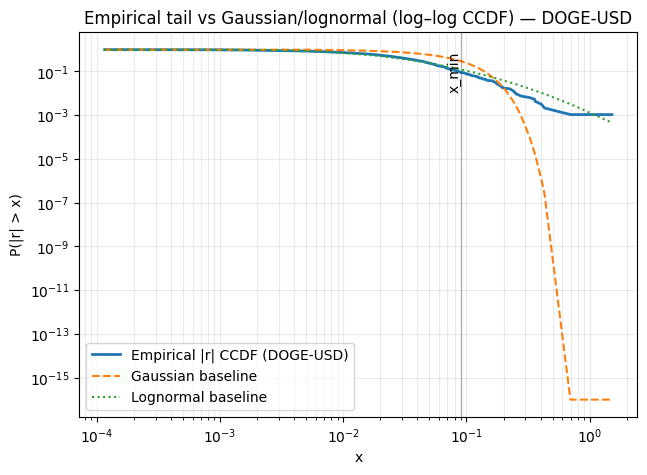

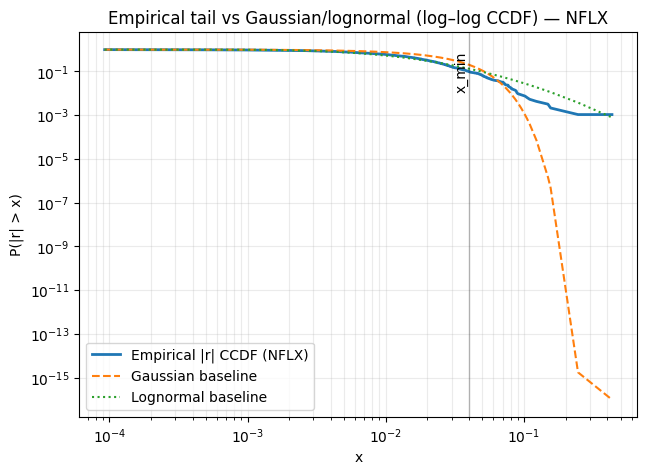

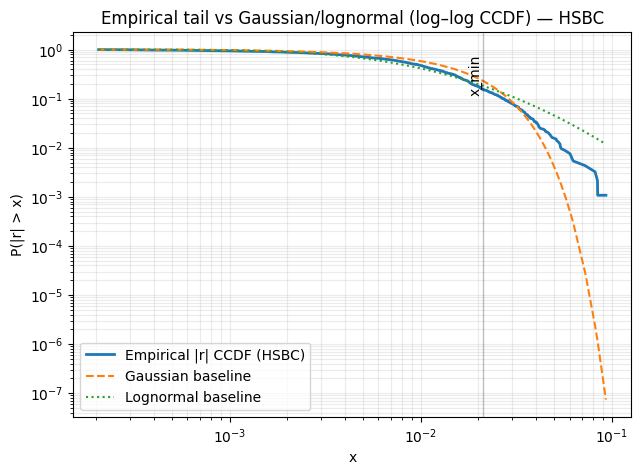


Interpretation (high-level):
- If empirical CCDF sits far above Gaussian/lognormal in the far right of the plot, extremes are more frequent than thin-tail models.
- Hill α estimates quantify tail heaviness: smaller α ⇒ fatter tail. In Lévy-stable terms, α<2 implies non-Gaussian heavy tails.
- α- vs α+ asymmetry: if α- < α+, downside tail is heavier (crashes more likely than rallies of same magnitude).
- Truncation check: if the fitted cutoff x_c is finite and the log–log plot bends downward at the far tail, behavior is consistent with a truncated Lévy flight / finite-size constraints.
- If you see an extended near-linear region on log–log axes (over a meaningful range), that supports scale-invariant power-law behavior on that range; strong curvature suggests finite-sample or cutoff effects.


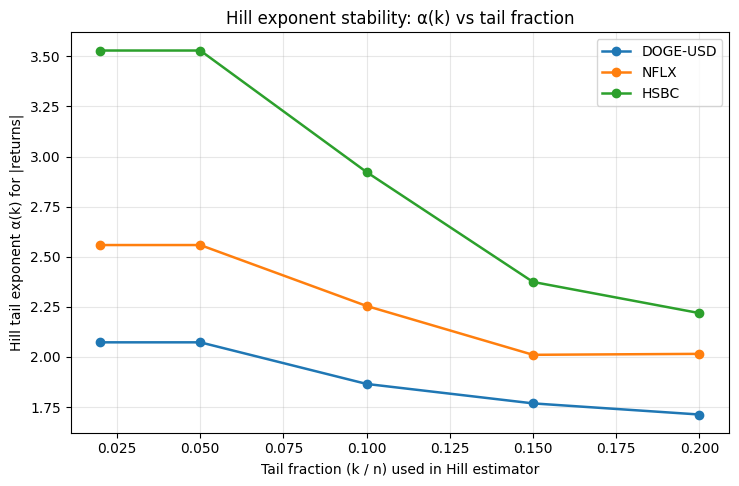


α(k) robustness summary (interpret as scale-dependent, not a single constant):
- DOGE-USD: α(k) over fractions [0.02, 0.05, 0.1, 0.15, 0.2] = [2.073, 2.073, 1.865, 1.768, 1.713] (Δ≈0.360) → shows a plausible plateau (tail exponent fairly robust over these thresholds).
- NFLX: α(k) over fractions [0.02, 0.05, 0.1, 0.15, 0.2] = [2.558, 2.558, 2.254, 2.011, 2.015] (Δ≈0.548) → mixed/weak stability (tail exponent depends on scale; choose threshold carefully).
- HSBC: α(k) over fractions [0.02, 0.05, 0.1, 0.15, 0.2] = [3.529, 3.529, 2.922, 2.374, 2.219] (Δ≈1.310) → strong threshold sensitivity (likely truncation/finite-size effects or no clean scale-free tail).

How to interpret: 
- A stable plateau across a range of k supports a robust power-law-like tail over that scale range.
- Monotonic drift or high noise means α is not stable: either the threshold includes non-tail data (bias) or the tail is truncated/finite-sample (curvature).
- This is the bias–variance tradeoff: small k = noisy but

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, lognorm

# ==================================================
# Sornette (Ch.4) style tail analysis on stock returns
#   Requirements: `log_returns` DataFrame exists (rows=time, cols=tickers)
# ==================================================

if "log_returns" not in globals():
    raise RuntimeError("`log_returns` not found. Run the earlier cell that computes log_returns first.")

R = log_returns.copy()
R = R.replace([np.inf, -np.inf], np.nan).dropna(how="all")

# ------------------------------
# Step 1) Empirical CCDF helper
# ------------------------------

def empirical_ccdf(x: np.ndarray):
    """Return sorted x (ascending) and empirical CCDF P(X > x)."""
    x = np.asarray(x, float)
    x = x[np.isfinite(x)]
    x = x[x > 0]
    if len(x) == 0:
        return np.array([]), np.array([])
    xs = np.sort(x)
    # CCDF at each xs[i]: fraction strictly greater than xs[i]
    ccdf = 1.0 - (np.arange(1, len(xs) + 1) / len(xs))
    # Avoid zeros for log plotting
    ccdf = np.clip(ccdf, 1.0 / len(xs), 1.0)
    return xs, ccdf


# -----------------------------------------------
# Step 2) Hill estimator for power-law exponent α
#   If tail is Pareto-like: P(X>x) ~ x^{-α}
# -----------------------------------------------

def hill_alpha(x_pos: np.ndarray, k: int) -> float:
    """Hill estimate of α using top-k order stats of positive samples x_pos."""
    x = np.asarray(x_pos, float)
    x = x[np.isfinite(x)]
    x = x[x > 0]
    if len(x) < k + 2:
        return np.nan
    x_sorted = np.sort(x)[::-1]  # descending
    xk = x_sorted[:k]
    xkp1 = x_sorted[k]  # (k+1)-th largest
    denom = np.mean(np.log(xk / xkp1))
    return float(1.0 / denom) if denom > 0 else np.nan


def choose_k_stable(x_pos: np.ndarray, k_min: int = 50, k_max_frac: float = 0.20, window: int = 25):
    """Pick k via a simple stability criterion on the Hill plot.

    Justification (practical, Sornette-style): choose a tail threshold where
    the Hill estimate is relatively stable vs k (bias–variance tradeoff).
    """
    x = np.asarray(x_pos, float)
    x = x[np.isfinite(x)]
    x = x[x > 0]
    n = len(x)
    if n < max(300, k_min + 5):
        return None, None, None

    k_max = int(max(k_min + 5, min(n - 2, np.floor(k_max_frac * n))))
    ks = np.arange(k_min, k_max + 1)
    alphas = np.array([hill_alpha(x, int(k)) for k in ks], dtype=float)

    # Smooth with a rolling median to reduce noise
    s = pd.Series(alphas).rolling(window=window, center=True, min_periods=max(5, window // 3)).median().to_numpy()

    # Measure local stability: absolute first-difference on smoothed curve
    ds = np.abs(np.diff(s))
    if len(ds) == 0 or not np.any(np.isfinite(ds)):
        return ks, alphas, None

    # Choose k in the middle 60% that minimizes local variation
    lo = int(0.20 * len(ds))
    hi = int(0.80 * len(ds))
    idx_range = np.arange(lo, max(lo + 1, hi))
    idx_range = idx_range[np.isfinite(ds[idx_range])]
    if len(idx_range) == 0:
        return ks, alphas, None

    best_i = int(idx_range[np.argmin(ds[idx_range])])
    k_star = int(ks[best_i])
    return ks, alphas, k_star


# ------------------------------------------------------------
# Step 3) Separate right vs left tails (α+ vs α-)
#   Right tail:  r | r>0
#   Left tail:  -r | r<0  (magnitude of negative returns)
# ------------------------------------------------------------

def tail_samples(r: np.ndarray):
    r = np.asarray(r, float)
    r = r[np.isfinite(r)]
    rp = r[r > 0]
    rm = (-r[r < 0])
    absr = np.abs(r)
    absr = absr[np.isfinite(absr)]
    absr = absr[absr > 0]
    return absr, rp, rm


# ----------------------------------------------------------------------
# Step 4) Truncated Lévy / cutoff check
#   Fit log CCDF ~ c - α log x - x/x_c  (power law with exponential cutoff)
#   If 1/x_c term is ~0 => close to pure power-law on fitted range.
# ----------------------------------------------------------------------

def fit_truncated_powerlaw(xs: np.ndarray, ccdf: np.ndarray, x_min: float):
    """Fit truncated model on points with x>=x_min.

    Returns (alpha_hat, x_c_hat, rmse, n_fit)
    """
    mask = (xs >= x_min) & np.isfinite(xs) & np.isfinite(ccdf) & (ccdf > 0)
    x = xs[mask]
    y = np.log(ccdf[mask])
    if len(x) < 30:
        return np.nan, np.nan, np.nan, int(len(x))

    # Design matrix: [1, log x, x]
    X = np.column_stack([np.ones_like(x), np.log(x), x])
    beta, *_ = np.linalg.lstsq(X, y, rcond=None)
    c0, b_logx, b_x = beta

    alpha_hat = float(-b_logx)
    x_c_hat = float(-1.0 / b_x) if b_x < 0 else np.inf  # exp(-x/x_c) => coefficient -1/x_c

    yhat = X @ beta
    rmse = float(np.sqrt(np.mean((y - yhat) ** 2)))
    return alpha_hat, x_c_hat, rmse, int(len(x))


# ------------------------------------------------------------
# Step 5) Run per-ticker + make plots for a small selection
# ------------------------------------------------------------

results = []

for ticker in R.columns:
    r = R[ticker].dropna().to_numpy(dtype=float)
    if len(r) < 300:
        continue

    absr, rp, rm = tail_samples(r)

    # --- Absolute tail α via Hill ---
    ks_abs, a_abs, k_abs = choose_k_stable(absr)
    alpha_abs = hill_alpha(absr, k_abs) if k_abs is not None else np.nan

    # Threshold x_min implied by Hill k* (the (k*+1)-th order statistic)
    x_min_abs = np.nan
    if k_abs is not None and len(absr) > k_abs + 1:
        x_sorted = np.sort(absr)[::-1]
        x_min_abs = float(x_sorted[k_abs])

    # --- Right tail α+ ---
    ks_p, a_p, k_p = choose_k_stable(rp)
    alpha_p = hill_alpha(rp, k_p) if k_p is not None else np.nan

    # --- Left tail α- (magnitudes) ---
    ks_m, a_m, k_m = choose_k_stable(rm)
    alpha_m = hill_alpha(rm, k_m) if k_m is not None else np.nan

    # --- Truncation / cutoff estimate on |r| CCDF ---
    xs, cc = empirical_ccdf(absr)
    alpha_tr, x_c, rmse_tr, n_fit = fit_truncated_powerlaw(xs, cc, x_min=x_min_abs) if np.isfinite(x_min_abs) else (np.nan, np.nan, np.nan, 0)

    # Asymmetry indicator: lower α => heavier tail
    asym = np.nan
    if np.isfinite(alpha_p) and np.isfinite(alpha_m) and alpha_p > 0 and alpha_m > 0:
        asym = float(alpha_m / alpha_p)  # >1 => right tail heavier; <1 => left tail heavier

    results.append(
        {
            "Ticker": ticker,
            "n": int(len(r)),
            "alpha_abs(Hill)": alpha_abs,
            "k_abs": k_abs,
            "x_min_abs": x_min_abs,
            "alpha_plus(Hill)": alpha_p,
            "alpha_minus(Hill)": alpha_m,
            "alpha_minus/alpha_plus": asym,
            "alpha_trunc_fit": alpha_tr,
            "x_cutoff": x_c,
            "trunc_rmse": rmse_tr,
            "trunc_n_fit": n_fit,
        }
    )

summary = pd.DataFrame(results).sort_values("alpha_abs(Hill)")

print("Step 1–2) Hill tail exponent estimates α for |returns| (smaller α = fatter tail)")
display(summary.head(10))

print("\nStep 3) Tail asymmetry (α- vs α+). If α- < α+, downside tail is heavier.")
display(
    summary[["Ticker", "alpha_plus(Hill)", "alpha_minus(Hill)", "alpha_minus/alpha_plus"]]
    .sort_values("alpha_minus/alpha_plus")
    .head(10)
)

print("\nStep 4) Truncated-Lévy / cutoff diagnostic: fit log CCDF ≈ c − α log x − x/x_c on x≥x_min")
display(summary[["Ticker", "x_min_abs", "alpha_trunc_fit", "x_cutoff", "trunc_rmse", "trunc_n_fit"]].head(10))

# ------------------------------------------------------------
# Step 5) Plots (empirical vs Gaussian vs lognormal baselines)
# ------------------------------------------------------------

# pick a few tickers: fattest tails by α_abs
plot_tickers = summary.head(3)["Ticker"].tolist()
if len(plot_tickers) == 0:
    raise RuntimeError("No tickers had enough data to estimate tails.")

for ticker in plot_tickers:
    r = R[ticker].dropna().to_numpy(dtype=float)
    absr = np.abs(r)
    absr = absr[np.isfinite(absr)]
    absr = absr[absr > 0]

    xs, cc = empirical_ccdf(absr)
    if len(xs) < 50:
        continue

    # Gaussian baseline for |r| using fitted mean/std of r
    mu = float(np.mean(r))
    sd = float(np.std(r)) if float(np.std(r)) > 0 else 1.0
    cc_gauss = 2.0 * norm.sf((xs - mu) / sd)
    cc_gauss = np.clip(cc_gauss, 1e-16, 1.0)

    # Lognormal baseline on |r| (purely as a light-tail reference)
    # Fit with loc fixed at 0 to avoid negative support
    try:
        s_hat, loc_hat, scale_hat = lognorm.fit(absr, floc=0)
        cc_logn = 1.0 - lognorm.cdf(xs, s=s_hat, loc=loc_hat, scale=scale_hat)
        cc_logn = np.clip(cc_logn, 1e-16, 1.0)
    except Exception:
        cc_logn = None

    plt.figure(figsize=(7.2, 5.0))
    plt.loglog(xs, cc, label=f"Empirical |r| CCDF ({ticker})", linewidth=2)
    plt.loglog(xs, cc_gauss, label="Gaussian baseline", linestyle="--")
    if cc_logn is not None:
        plt.loglog(xs, cc_logn, label="Lognormal baseline", linestyle=":")

    # Mark x_min used for |r| Hill estimate (if available)
    row = summary[summary["Ticker"] == ticker].iloc[0]
    if np.isfinite(row["x_min_abs"]):
        plt.axvline(row["x_min_abs"], color="k", alpha=0.25, linewidth=1)
        plt.text(row["x_min_abs"], 0.8, "x_min", rotation=90, va="top", ha="right")

    plt.xlabel("x")
    plt.ylabel("P(|r| > x)")
    plt.title(f"Empirical tail vs Gaussian/lognormal (log–log CCDF) — {ticker}")
    plt.grid(True, which="both", alpha=0.25)
    plt.legend()
    plt.show()

# ------------------------------------------------------------
# Step 6) Interpretation (Sornette-style)
# ------------------------------------------------------------

print("\nInterpretation (high-level):")
print("- If empirical CCDF sits far above Gaussian/lognormal in the far right of the plot, extremes are more frequent than thin-tail models.")
print("- Hill α estimates quantify tail heaviness: smaller α ⇒ fatter tail. In Lévy-stable terms, α<2 implies non-Gaussian heavy tails.")
print("- α- vs α+ asymmetry: if α- < α+, downside tail is heavier (crashes more likely than rallies of same magnitude).")
print("- Truncation check: if the fitted cutoff x_c is finite and the log–log plot bends downward at the far tail, behavior is consistent with a truncated Lévy flight / finite-size constraints.")
print("- If you see an extended near-linear region on log–log axes (over a meaningful range), that supports scale-invariant power-law behavior on that range; strong curvature suggests finite-sample or cutoff effects.")

# ==================================================
# Robustness check: Hill α(k) vs tail size k (Sornette-style)
#   Goal: see whether α is stable (plateau) across reasonable tail thresholds.
# ==================================================

# Step A) Choose tickers to test
# By default: reuse the same tickers we plotted above (fattest tails by α_abs)
selected_tickers = plot_tickers

# Step B) Choose tail fractions (top % of |returns|)
# These correspond to the number of order statistics k used in the Hill estimator.
tail_fracs = [0.02, 0.05, 0.10, 0.15, 0.20]

# Step C) Compute α(k) for each ticker and each tail fraction
alpha_curves = {}

for ticker in selected_tickers:
    if ticker not in R.columns:
        continue

    r = R[ticker].dropna().to_numpy(dtype=float)
    absr = np.abs(r)
    absr = absr[np.isfinite(absr)]
    absr = absr[absr > 0]

    n = len(absr)
    if n < 400:
        continue

    ks = []
    alphas = []

    for f in tail_fracs:
        k = int(np.floor(f * n))
        k = max(50, min(k, n - 2))
        a = hill_alpha(absr, k)
        ks.append(k)
        alphas.append(a)

    alpha_curves[ticker] = {
        "n": n,
        "tail_fracs": np.array(tail_fracs, float),
        "ks": np.array(ks, int),
        "alphas": np.array(alphas, float),
    }

# Step D) Plot α vs tail fraction (combined plot)
plt.figure(figsize=(8.5, 5.2))

for ticker, d in alpha_curves.items():
    x = d["tail_fracs"]
    y = d["alphas"]
    plt.plot(x, y, marker="o", linewidth=1.8, label=ticker)

plt.xlabel("Tail fraction (k / n) used in Hill estimator")
plt.ylabel("Hill tail exponent α(k) for |returns|")
plt.title("Hill exponent stability: α(k) vs tail fraction")
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

# Step E) Mark stable vs unstable regions (simple local-variation heuristic)
# Plateau idea: α(k) changes little as k varies within a reasonable range.
# Drift/noise: α(k) moves a lot (threshold sensitivity, contamination, truncation, or too little data).

def plateau_mask(alphas: np.ndarray, tol: float = 0.15):
    """Return a boolean mask where local step-to-step changes are small.

    tol is absolute change threshold in α between adjacent fractions.
    """
    a = np.asarray(alphas, float)
    da = np.abs(np.diff(a))
    ok = da < tol
    # mark points that are part of a stable transition (either side of a small step)
    mask = np.zeros_like(a, dtype=bool)
    if len(ok) > 0:
        mask[:-1] |= ok
        mask[1:] |= ok
    return mask

print("\nα(k) robustness summary (interpret as scale-dependent, not a single constant):")

for ticker, d in alpha_curves.items():
    fr = d["tail_fracs"]
    ks = d["ks"]
    al = d["alphas"]

    stable = plateau_mask(al, tol=0.15)
    n_stable = int(np.sum(stable))

    # crude diagnostics
    a_min, a_max = float(np.nanmin(al)), float(np.nanmax(al))
    drift = a_max - a_min

    msg = f"- {ticker}: α(k) over fractions {list(fr)} = {np.round(al, 3).tolist()} (Δ≈{drift:.3f})"

    if n_stable >= 3 and drift < 0.5:
        msg += " → shows a plausible plateau (tail exponent fairly robust over these thresholds)."
    elif drift >= 0.8:
        msg += " → strong threshold sensitivity (likely truncation/finite-size effects or no clean scale-free tail)."
    else:
        msg += " → mixed/weak stability (tail exponent depends on scale; choose threshold carefully)."

    print(msg)

print("\nHow to interpret: ")
print("- A stable plateau across a range of k supports a robust power-law-like tail over that scale range.")
print("- Monotonic drift or high noise means α is not stable: either the threshold includes non-tail data (bias) or the tail is truncated/finite-sample (curvature).")
print("- This is the bias–variance tradeoff: small k = noisy but purer extremes; large k = smoother but contaminated by the bulk.")
